# HumanEval+ — capability, robustness and repeatability

**Research objective.** Estimate Python code-generation correctness using the fixed 164-task HumanEval/HumanEval+ benchmark and quantify (a) sensitivity to the selected tasks, (b) run-to-run variation, and (c) whether the chosen generation concurrency coincides with changes in correctness. **Concurrency is primarily a collection-time choice, not a capability metric.**

**Pinned evaluation:** EvalPlus v0.3.1, commit `e5d0ed0bab96280b60b637ec7f15b5e4841b0cb2`; HumanEval+ v0.1.10, dataset MD5 `fe585eb4df8c88d844eeb463ea4d0302`; 164 tasks; one completion per task/run; `temperature=0`, seed 0, `max_tokens=768`, and local truncation at configured stop strings. Pin the exact **model and tokenizer revision**, vLLM version, and server flags in the thesis methodology separately: these are not embedded in the evaluation result files.

**Primary endpoint:** HumanEval+ joint success: `base_status == "pass"` **and** `plus_status == "pass"`. **Secondary endpoint:** original HumanEval success: `base_status == "pass"`. A HumanEval+ score with one generated solution per task is the observed pass@1 for that run.

**Data layout:** `capability/results/humanevalplus/generated/c8/google--gemma-2b_run-1.jsonl` and `evaluated/c8/google--gemma-2b_run-1_eval_results.json`. A historic, flat `gemma-2b_run01_eval_results.json` is a **pilot** and excluded from measured aggregates.

**Important limitations:** all runs use the same 164 tasks; 2,460 task-run outcomes do **not** constitute 2,460 independent tasks. Bootstrap intervals below resample whole *task identities*, preserving their outcomes across repetitions and concurrencies. Three repetitions per concurrency offer only a preliminary assessment of run variability. We report descriptive findings rather than attributing changes causally to concurrency.

**Execution and safety:** the notebook only parses data and creates figures; it never executes generated Python. The benchmark code ran exclusively in the offline evaluation VM. Newly added analyses may initially show no cached output: run all notebook cells in the repository environment to populate them.


## 1. Discover and validate the original EvalPlus results

Each measured file must contain all **164 distinct task IDs**, with exactly one completion per task. Import original pass/fail fields rather than inferring correctness from generated text. Select a single model so unrelated model capabilities are not pooled.


In [1]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

MODEL = "google--gemma-2b"  # Flattened full Hugging Face model ID.
PILOT_MODEL = "gemma-2b"
EXPECTED_HASH = "fe585eb4df8c88d844eeb463ea4d0302"
TASK_IDS = [f"HumanEval/{i}" for i in range(164)]
EXPECTED_TASKS = set(TASK_IDS)
BOOTSTRAP_DRAWS = 5000
BOOTSTRAP_SEED = 12345

# Works when launched from the repository root or capability/notebooks/.
CANDIDATES = [
  Path("capability/results/humanevalplus"),
  Path("../results/humanevalplus"),
  Path("../capability/results/humanevalplus"),
  Path("."),
]
RESULTS_ROOT = next((p for p in CANDIDATES if p.exists() and (
  any(p.glob("evaluated/c*/*_eval_results.json")) or
  any(p.glob("*_eval_results.json"))
)), None)
if RESULTS_ROOT is None:
  raise FileNotFoundError("Set RESULTS_ROOT to the HumanEval+ results directory")
print("Results root:", RESULTS_ROOT.resolve())

Results root: /home/toporek3112/Projects/llm_benchmarks/capability/results/humanevalplus


In [2]:
MEASURED_PATTERN = re.compile(r"^(?P<model>[A-Za-z0-9._-]+)_run-(?P<run>\d+)_eval_results\.json$")
PILOT_PATTERN = re.compile(r"^gemma-2b_run(?P<run>\d+)_eval_results\.json$")


def identify_run(path):
  group = re.fullmatch(r"c([1-9]\d*)", path.parent.name)
  matched = MEASURED_PATTERN.fullmatch(path.name)
  if group and matched and matched["model"] == MODEL:
    concurrency = int(group[1])
    repetition = int(matched["run"])
    return "measured", concurrency, repetition, f"c{concurrency}_{MODEL}_run-{repetition}"
  pilot = PILOT_PATTERN.fullmatch(path.name)
  if path.parent == RESULTS_ROOT and pilot and MODEL == "google--gemma-2b":
    return "pilot", 1, int(pilot["run"]), path.stem.removesuffix("_eval_results")
  return None


def load_evaluation(path):
  data = json.loads(path.read_text(encoding="utf-8"))
  if data.get("hash") != EXPECTED_HASH:
    raise ValueError(f"Wrong dataset hash: {path}")
  if set(data.get("eval", {})) != EXPECTED_TASKS:
    raise ValueError(f"Incomplete or unexpected task identities: {path}")
  rows = []
  for task_id, samples in data["eval"].items():
    if not isinstance(samples, list) or len(samples) != 1 or samples[0].get("task_id") != task_id:
      raise ValueError(f"Expected one result for {task_id}: {path}")
    record = samples[0]
    b = record["base_status"] == "pass"
    p = record["plus_status"] == "pass"
    rows.append({
      "task_id": task_id,
      "base_status": record["base_status"],
      "plus_status": record["plus_status"],
      "base_pass": int(b),
      "plus_pass": int(b and p),
      "solution": record["solution"],
    })
  return rows


paths = sorted(RESULTS_ROOT.glob("evaluated/c*/*_eval_results.json"))
paths += sorted(RESULTS_ROOT.glob("*_eval_results.json"))
records = []
for path in paths:
  metadata = identify_run(path)
  if metadata is None:
    print("Skipping unselected run:", path)
    continue
  phase, concurrency, repetition, run = metadata
  for task in load_evaluation(path):
    records.append({
      "run": run,
      "phase": phase,
      "concurrency": concurrency,
      "repetition": repetition,
      "file": str(path.relative_to(RESULTS_ROOT)),
      **task,
    })

outcomes = pd.DataFrame(records)
if outcomes.empty:
  raise ValueError("No valid evaluated runs found for MODEL")
if outcomes.duplicated(["run", "task_id"]).any():
  raise ValueError("Duplicate run/task pairs")
print(f"Loaded {outcomes.run.nunique()} full runs; {len(outcomes)} per-task outcomes")
display(outcomes.groupby(["phase", "concurrency", "run"], as_index=False)
  .agg(tasks=("task_id", "size"), humaneval=("base_pass", "sum"), humaneval_plus=("plus_pass", "sum")))

Loaded 15 full runs; 2460 per-task outcomes


,phase,concurrency,run,tasks,humaneval,humaneval_plus
0,measured,8,c8_google--gemma-2b_run-1,164,36,28
1,measured,8,c8_google--gemma-2b_run-2,164,36,28
2,measured,8,c8_google--gemma-2b_run-3,164,37,29
3,measured,32,c32_google--gemma-2b_run-1,164,36,28
4,measured,32,c32_google--gemma-2b_run-2,164,36,28
5,measured,32,c32_google--gemma-2b_run-3,164,36,28
6,measured,64,c64_google--gemma-2b_run-1,164,35,27
7,measured,64,c64_google--gemma-2b_run-2,164,37,28
8,measured,64,c64_google--gemma-2b_run-3,164,35,27
9,measured,128,c128_google--gemma-2b_run-1,164,37,28


### 1.1. Study completeness and status sanity checks

Verify that all planned **5 × 3 = 15** runs are present. A `plus_status` of `pass` without `base_status` of `pass` is possible; the joint criterion is therefore required. Failures or timeouts should be counted as unsuccessful, not dropped. Summarize all status strings to reveal unexpected values rather than silently assuming they are all `fail`.


In [3]:
EXPECTED_CONCURRENCIES = [8, 32, 64, 128, 256]
EXPECTED_REPETITIONS = [1, 2, 3]

measured_audit = outcomes[outcomes.phase == "measured"].copy()
expected_cells = {(c, r) for c in EXPECTED_CONCURRENCIES for r in EXPECTED_REPETITIONS}
observed_cells = set(zip(measured_audit.concurrency, measured_audit.repetition))
missing_cells = sorted(expected_cells - observed_cells)
extra_cells = sorted(observed_cells - expected_cells)

print(f"Expected design: {len(expected_cells)} runs; found: {len(observed_cells)}")
print("Missing cells:", missing_cells if missing_cells else "none")
print("Extra cells:", extra_cells if extra_cells else "none")
if measured_audit.empty:
  print("No measured runs found yet.")
else:
  display(pd.crosstab(measured_audit.base_status, measured_audit.plus_status,
    rownames=["Base-test status"], colnames=["Extra-test status"]))
  unusual = measured_audit[
    (measured_audit.base_status != "pass") & (measured_audit.plus_status == "pass")
  ]
  print(f"Extra-test passes without base-test success: {len(unusual)} task-run observations")
  if len(unusual):
    display(unusual[["run", "task_id", "base_status", "plus_status"]].head(12))
  if missing_cells:
    print("WARNING: Analyses below use the available runs, not the intended complete design.")


Expected design: 15 runs; found: 15
Missing cells: none
Extra cells: none


Extra-test status,fail,pass
Base-test status,,
fail,1904,15
pass,124,417


Extra-test passes without base-test success: 15 task-run observations


,run,task_id,base_status,plus_status
16,c128_google--gemma-2b_run-1,HumanEval/92,fail,pass
181,c128_google--gemma-2b_run-2,HumanEval/92,fail,pass
346,c128_google--gemma-2b_run-3,HumanEval/92,fail,pass
515,c256_google--gemma-2b_run-1,HumanEval/92,fail,pass
679,c256_google--gemma-2b_run-2,HumanEval/92,fail,pass
840,c256_google--gemma-2b_run-3,HumanEval/92,fail,pass
1049,c32_google--gemma-2b_run-1,HumanEval/92,fail,pass
1215,c32_google--gemma-2b_run-2,HumanEval/92,fail,pass
1376,c32_google--gemma-2b_run-3,HumanEval/92,fail,pass
1514,c64_google--gemma-2b_run-1,HumanEval/92,fail,pass


### 1.2. Artifact integrity and reproducibility audit (when metadata is available)

The evaluator's dataset hash alone is insufficient to prove which generated JSONL was evaluated. Check the **generation JSONL SHA256** against its generation manifest and the **evaluation JSON SHA256** against its evaluation manifest. Also check the link between generated and evaluated SHA256 hashes. This is a local *integrity check*, not cryptographic authentication of downloaded model weights or software.

A missing historic manifest is reported as **unavailable**, not treated as verified. An explicit **hash mismatch raises an error** and should be investigated before using the results in a thesis. For reproducibility, retain generation/evaluation scripts, exact model and tokenizer revisions, evaluator commit, all JSONL/JSON outputs, and relevant server parameters.


In [4]:
import hashlib

if measured_audit.empty:
  print("No measured runs to audit")
else:
  provenance_rows = []
  for run_data in measured_audit[["run", "concurrency", "repetition", "file"]].drop_duplicates().itertuples(index=False):
    run_name = f"{MODEL}_run-{run_data.repetition}"
    generated_path = (RESULTS_ROOT / "generated" / f"c{run_data.concurrency}" / f"{run_name}.jsonl")
    evaluated_path = RESULTS_ROOT / run_data.file
    generated_manifest_path = generated_path.with_suffix(".manifest.json")
    evaluation_manifest_path = evaluated_path.with_name(f"{run_name}.evaluation_manifest.json")
    generated_sha256 = None
    generation_verified = "metadata unavailable"
    evaluation_verified = "metadata unavailable"

    if generated_path.is_file():
      generated_sha256 = hashlib.sha256(generated_path.read_bytes()).hexdigest()
      if generated_manifest_path.is_file():
        generation_manifest = json.loads(generated_manifest_path.read_text(encoding="utf-8"))
        if generation_manifest.get("generated_sha256") != generated_sha256:
          raise ValueError(f"Generation checksum mismatch: {generated_path}")
        if generation_manifest.get("dataset_md5") != EXPECTED_HASH:
          raise ValueError(f"Dataset hash mismatch: {generated_manifest_path}")
        if generation_manifest.get("evalplus_commit") != "e5d0ed0bab96280b60b637ec7f15b5e4841b0cb2":
          raise ValueError(f"Evaluator pin mismatch: {generated_manifest_path}")
        generation_verified = "SHA256 verified"

    if evaluation_manifest_path.is_file():
      evaluation_manifest = json.loads(evaluation_manifest_path.read_text(encoding="utf-8"))
      evaluated_sha256 = hashlib.sha256(evaluated_path.read_bytes()).hexdigest()
      if evaluation_manifest.get("evaluated_sha256") != evaluated_sha256:
        raise ValueError(f"Evaluation checksum mismatch: {evaluated_path}")
      if generated_sha256 is not None and evaluation_manifest.get("generated_sha256") != generated_sha256:
        raise ValueError(f"Evaluation references a different generated input: {evaluated_path}")
      if evaluation_manifest.get("dataset_md5") != EXPECTED_HASH:
        raise ValueError(f"Dataset hash mismatch: {evaluation_manifest_path}")
      evaluation_verified = "SHA256 verified"

    provenance_rows.append({
      "run": run_data.run,
      "generation integrity": generation_verified,
      "evaluation integrity": evaluation_verified,
    })
  provenance = pd.DataFrame(provenance_rows)
  display(provenance)
  if (provenance[["generation integrity", "evaluation integrity"]] == "metadata unavailable").any().any():
    print("NOTE: Unavailable metadata limits provenance claims, but does not invalidate the EvalPlus score itself.")


,run,generation integrity,evaluation integrity
0,c128_google--gemma-2b_run-1,SHA256 verified,SHA256 verified
1,c128_google--gemma-2b_run-2,SHA256 verified,SHA256 verified
2,c128_google--gemma-2b_run-3,SHA256 verified,SHA256 verified
3,c256_google--gemma-2b_run-1,SHA256 verified,SHA256 verified
4,c256_google--gemma-2b_run-2,SHA256 verified,SHA256 verified
5,c256_google--gemma-2b_run-3,SHA256 verified,SHA256 verified
6,c32_google--gemma-2b_run-1,SHA256 verified,SHA256 verified
7,c32_google--gemma-2b_run-2,SHA256 verified,SHA256 verified
8,c32_google--gemma-2b_run-3,SHA256 verified,SHA256 verified
9,c64_google--gemma-2b_run-1,SHA256 verified,SHA256 verified


## 2. Pilot — optional, excluded from measured estimates

If the historical pilot is present in the repository, display its score separately. The pilot is a workflow validation, not another repetition at a measured concurrency. A **task bootstrap** resamples task IDs and quantifies sensitivity to the *choice of benchmark problems*; it does not estimate variation between future generations.

In the supplied executed notebook, **the pilot was not found**, so no pilot score is included in the 15-run analysis.


In [5]:
def task_bootstrap(frame, draws=BOOTSTRAP_DRAWS, seed=BOOTSTRAP_SEED):
  ordered = frame.set_index("task_id").reindex(TASK_IDS)
  values = ordered[["base_pass", "plus_pass"]].to_numpy(dtype=float)
  rng = np.random.default_rng(seed)
  indices = rng.integers(0, len(values), size=(draws, len(values)))
  samples = values[indices].mean(axis=1)
  return values.mean(axis=0), np.quantile(samples, [0.025, 0.975], axis=0)


pilots = outcomes.loc[outcomes.phase == "pilot", "run"].unique()
if len(pilots):
  pilot = outcomes[outcomes.run == sorted(pilots)[0]].copy()
  score, ci = task_bootstrap(pilot)
  display(pd.DataFrame({
    "benchmark": ["HumanEval", "HumanEval+ (joint)"],
    "passes": [int(pilot.base_pass.sum()), int(pilot.plus_pass.sum())],
    "total": [164, 164],
    "pass@1 (%)": np.round(100 * score, 2),
    "task-bootstrap low (%)": np.round(100 * ci[0], 2),
    "task-bootstrap high (%)": np.round(100 * ci[1], 2),
  }))
  display(pd.crosstab(pilot.base_status, pilot.plus_status,
    rownames=["Base tests"], colnames=["Additional tests"]))
else:
  print("No historical pilot found (this is fine once measured runs exist).")

No historical pilot found (this is fine once measured runs exist).


## 3. Capability scores across the 15 measured runs

Compute one score per run before aggregating. The overall mean/median/SD describe the **balanced mixture of five concurrency settings** (three runs each), not an estimate at one fixed concurrency. Interpret the within-concurrency SD separately; with only three repetitions and a score resolution of **1/164 = 0.61 percentage points**, small or zero observed SD is not proof of deterministic outputs.

**Results in the supplied executed notebook:** HumanEval **21.99%** mean, **21.95%** median, **0.49 pp** run-level SD; HumanEval+ **16.95%** mean, **17.07%** median, **0.34 pp** run-level SD. Across the measured configurations, HumanEval+ means range from **16.67% to 17.28%** (a spread of **0.61 pp**, approximately one task). These differences are descriptive, not evidence of a causal concurrency effect.


In [6]:
measured = outcomes[outcomes.phase == "measured"].copy()


def describe_runs(frame, col):
  series = frame[col]
  return {
    "runs": len(series),
    "mean (%)": series.mean(),
    "median (%)": series.median(),
    "SD runs (pp)": series.std(ddof=1) if len(series) > 1 else np.nan,
    "min (%)": series.min(),
    "max (%)": series.max(),
  }


if measured.empty:
  print("No measured runs yet. Add evaluated/cN/*_eval_results.json files.")
else:
  run_scores = (measured.groupby(["run", "concurrency", "repetition"], as_index=False)
    .agg(base_score=("base_pass", "mean"), plus_score=("plus_pass", "mean")))
  run_scores[["base_score", "plus_score"]] *= 100
  display(run_scores.sort_values(["concurrency", "repetition"]).round(2))

  for label, col in [("HumanEval", "base_score"), ("HumanEval+", "plus_score")]:
    display(Markdown(f"**{label}: overall measured runs**"))
    display(pd.DataFrame([describe_runs(run_scores, col)]).round(2))
    display(Markdown(f"**{label}: grouped by generation concurrency**"))
    grouped = [{"concurrency": c, **describe_runs(part, col)}
               for c, part in run_scores.groupby("concurrency")]
    display(pd.DataFrame(grouped).round(2))

,run,concurrency,repetition,base_score,plus_score
12,c8_google--gemma-2b_run-1,8,1,21.95,17.07
13,c8_google--gemma-2b_run-2,8,2,21.95,17.07
14,c8_google--gemma-2b_run-3,8,3,22.56,17.68
6,c32_google--gemma-2b_run-1,32,1,21.95,17.07
7,c32_google--gemma-2b_run-2,32,2,21.95,17.07
8,c32_google--gemma-2b_run-3,32,3,21.95,17.07
9,c64_google--gemma-2b_run-1,64,1,21.34,16.46
10,c64_google--gemma-2b_run-2,64,2,22.56,17.07
11,c64_google--gemma-2b_run-3,64,3,21.34,16.46
0,c128_google--gemma-2b_run-1,128,1,22.56,17.07


**HumanEval: overall measured runs**

,runs,mean (%),median (%),SD runs (pp),min (%),max (%)
0,15,21.99,21.95,0.49,21.34,22.56


**HumanEval: grouped by generation concurrency**

,concurrency,runs,mean (%),median (%),SD runs (pp),min (%),max (%)
0,8,3,22.15,21.95,0.35,21.95,22.56
1,32,3,21.95,21.95,0.00,21.95,21.95
2,64,3,21.75,21.34,0.70,21.34,22.56
3,128,3,22.56,22.56,0.00,22.56,22.56
4,256,3,21.54,21.34,0.35,21.34,21.95


**HumanEval+: overall measured runs**

,runs,mean (%),median (%),SD runs (pp),min (%),max (%)
0,15,16.95,17.07,0.34,16.46,17.68


**HumanEval+: grouped by generation concurrency**

,concurrency,runs,mean (%),median (%),SD runs (pp),min (%),max (%)
0,8,3,17.28,17.07,0.35,17.07,17.68
1,32,3,17.07,17.07,0.00,17.07,17.07
2,64,3,16.67,16.46,0.35,16.46,17.07
3,128,3,17.07,17.07,0.00,17.07,17.07
4,256,3,16.67,16.46,0.35,16.46,17.07


### 3.1. Between-run variation **within** fixed concurrency settings

The overall SD mixes (small) differences among settings with changes between repetitions at the *same* setting. A pooled within-setting SD estimates the observed repetition-level variation more directly. It is **descriptive only**: with three runs in each group, the precision of an SD estimate is limited and zero empirical SD is not a guarantee of identical future results.


In [7]:
if not measured.empty:
  within_rows = []
  for benchmark, column in [("HumanEval", "base_score"), ("HumanEval+", "plus_score")]:
    parts = [group[column].to_numpy(dtype=float)
      for _, group in run_scores.groupby("concurrency") if len(group) >= 2]
    within_df = sum(len(values) - 1 for values in parts)
    within_ss = sum(((values - values.mean()) ** 2).sum() for values in parts)
    pooled_sd = np.sqrt(within_ss / within_df) if within_df else np.nan
    within_rows.append({
      "benchmark": benchmark,
      "observed pooled within-concurrency SD (pp)": pooled_sd,
      "degrees of freedom": within_df,
      "overall across-concurrency SD (pp)": run_scores[column].std(ddof=1),
    })
  display(pd.DataFrame(within_rows).round(3))


,benchmark,observed pooled within-concurrency SD (pp),degrees of freedom,overall across-concurrency SD (pp)
0,HumanEval,0.386,10,0.487
1,HumanEval+,0.273,10,0.342


## 4. Task-selection uncertainty (paired, clustered bootstrap)

A bootstrap draw resamples the same 164 **task identities** across *all* runs. Keeping a task's repeated observations together preserves their dependence. Intervals describe **sensitivity to hypothetical resampling of task identities**; they are **not** CIs for a fixed benchmark score, between-run SD, or a prediction interval for the next run.

**Observed HumanEval+ overall 95% task-bootstrap interval:** **11.59–22.89%** around the measured mean of **16.95%**. The interval is broad despite a run-level SD of only **0.34 pp**: a stable score on these 164 problems can still be sensitive to which problems are represented. Do not interpret `164 × 15 = 2,460` as the number of independent benchmark questions.


In [8]:
if not measured.empty:
  rng = np.random.default_rng(BOOTSTRAP_SEED)
  indices = rng.integers(0, len(TASK_IDS), size=(BOOTSTRAP_DRAWS, len(TASK_IDS)))

  def clustered_ci(frame, col):
    matrix = frame.pivot(index="task_id", columns="run", values=col).reindex(TASK_IDS)
    if matrix.isna().any().any():
      raise ValueError("An incomplete run was detected during bootstrap")
    a = matrix.to_numpy(dtype=float)
    bs = a[indices].mean(axis=(1, 2))
    low, high = np.quantile(bs, [0.025, 0.975])
    return 100 * a.mean(), 100 * low, 100 * high

  ci_rows = []
  for label, col in [("HumanEval", "base_pass"), ("HumanEval+", "plus_pass")]:
    for group_name, part in [("overall", measured)] + [
      (f"c{c}", part) for c, part in measured.groupby("concurrency")
    ]:
      point, low, high = clustered_ci(part, col)
      ci_rows.append({
        "benchmark": label,
        "group": group_name,
        "runs": part.run.nunique(),
        "mean pass@1 (%)": point,
        "95% task CI low (%)": low,
        "95% task CI high (%)": high,
      })
  interval_table = pd.DataFrame(ci_rows)
  display(interval_table.round(2))

,benchmark,group,runs,mean pass@1 (%),95% task CI low (%),95% task CI high (%)
0,HumanEval,overall,15,21.99,15.89,28.37
1,HumanEval,c8,3,22.15,15.85,28.66
2,HumanEval,c32,3,21.95,15.85,28.66
3,HumanEval,c64,3,21.75,15.65,28.05
4,HumanEval,c128,3,22.56,16.46,29.27
5,HumanEval,c256,3,21.54,15.45,27.85
6,HumanEval+,overall,15,16.95,11.59,22.89
7,HumanEval+,c8,3,17.28,11.79,23.17
8,HumanEval+,c32,3,17.07,11.59,23.17
9,HumanEval+,c64,3,16.67,11.38,22.56


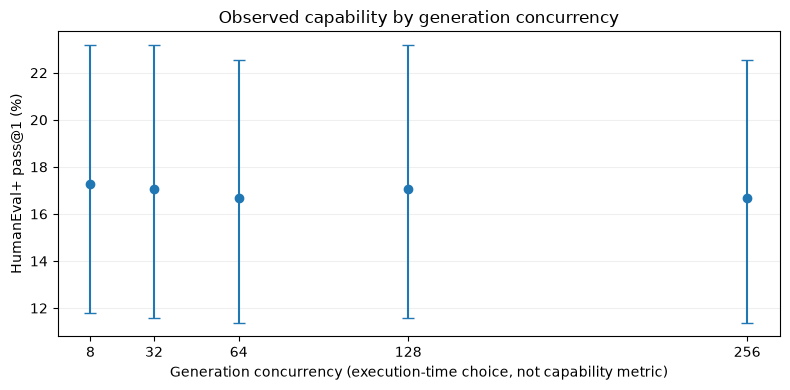

In [9]:
if not measured.empty:
  view = interval_table[(interval_table.benchmark == "HumanEval+") &
    (interval_table.group != "overall")].copy()
  view["concurrency"] = view.group.str.removeprefix("c").astype(int)
  view = view.sort_values("concurrency")
  means = view["mean pass@1 (%)"].to_numpy()
  low = view["95% task CI low (%)"].to_numpy()
  high = view["95% task CI high (%)"].to_numpy()
  fig, ax = plt.subplots(figsize=(8, 4))
  ax.errorbar(view.concurrency.to_numpy(), means,
    yerr=[means - low, high - means], fmt="o", capsize=4)
  ax.set_xticks(view.concurrency)
  ax.set_xlabel("Generation concurrency (execution-time choice, not capability metric)")
  ax.set_ylabel("HumanEval+ pass@1 (%)")
  ax.set_title("Observed capability by generation concurrency")
  ax.grid(axis="y", alpha=0.2)
  plt.tight_layout()
  plt.show()

## 5. What additional tests reveal: HumanEval versus HumanEval+

A base-test pass is **not** sufficient for joint HumanEval+ success. We calculate the *paired* reduction in pass@1 for exactly the same generated solutions. The difference is measured in percentage points (pp); the conditional retention rate reports what fraction of base-passing solutions also pass the additional tests.

In the supplied 15-run snapshot, the mean scores drop from **21.99%** (HumanEval) to **16.95%** (HumanEval+), a **5.04 pp absolute decrease**, or approximately **22.9% relative to the HumanEval mean**. This is direct evidence that the stronger test suite detects additional failures in this evaluation protocol; it is not evidence that the model became less capable. HumanEval+ is the primary endpoint because it is the stricter criterion.


In [10]:
if not measured.empty:
  measured["extra_tests_lost_pass"] = measured.base_pass - measured.plus_pass
  attrition = (measured.groupby(["concurrency", "repetition", "run"], as_index=False)
    .agg(base_passes=("base_pass", "sum"),
         joint_passes=("plus_pass", "sum"),
         lost_passes=("extra_tests_lost_pass", "sum")))
  attrition["retained base passes (%)"] = np.where(
    attrition.base_passes > 0,
    100 * attrition.joint_passes / attrition.base_passes,
    np.nan,
  )
  display(attrition.round(2))

  # The paired task bootstrap draws whole question IDs across all runs.
  paired_matrix = (measured.pivot(index="task_id", columns="run", values="extra_tests_lost_pass")
    .reindex(TASK_IDS))
  if paired_matrix.isna().any().any():
    raise ValueError("Incomplete task matrix for paired test-suite comparison")
  loss_values = paired_matrix.to_numpy(dtype=float)
  rng = np.random.default_rng(BOOTSTRAP_SEED + 100)
  idx = rng.integers(0, len(TASK_IDS), size=(BOOTSTRAP_DRAWS, len(TASK_IDS)))
  loss_bootstrap = 100 * loss_values[idx].mean(axis=(1, 2))
  loss_ci = np.quantile(loss_bootstrap, [0.025, 0.975])
  base_mean = measured.base_pass.mean()
  plus_mean = measured.plus_pass.mean()
  summary = pd.DataFrame([{
    "base pass@1 (%)": 100 * base_mean,
    "joint plus pass@1 (%)": 100 * plus_mean,
    "absolute loss (pp)": 100 * (base_mean - plus_mean),
    "relative loss from base (%)": 100 * (1 - plus_mean / base_mean) if base_mean else np.nan,
    "base-pass retention (%)": 100 * plus_mean / base_mean if base_mean else np.nan,
    "95% task CI for loss low (pp)": loss_ci[0],
    "95% task CI for loss high (pp)": loss_ci[1],
  }])
  display(summary.round(2))


,concurrency,repetition,run,base_passes,joint_passes,lost_passes,retained base passes (%)
0,8,1,c8_google--gemma-2b_run-1,36,28,8,77.78
1,8,2,c8_google--gemma-2b_run-2,36,28,8,77.78
2,8,3,c8_google--gemma-2b_run-3,37,29,8,78.38
3,32,1,c32_google--gemma-2b_run-1,36,28,8,77.78
4,32,2,c32_google--gemma-2b_run-2,36,28,8,77.78
5,32,3,c32_google--gemma-2b_run-3,36,28,8,77.78
6,64,1,c64_google--gemma-2b_run-1,35,27,8,77.14
7,64,2,c64_google--gemma-2b_run-2,37,28,9,75.68
8,64,3,c64_google--gemma-2b_run-3,35,27,8,77.14
9,128,1,c128_google--gemma-2b_run-1,37,28,9,75.68


,base pass@1 (%),joint plus pass@1 (%),absolute loss (pp),relative loss from base (%),base-pass retention (%),95% task CI for loss low (pp),95% task CI for loss high (pp)
0,21.99,16.95,5.04,22.92,77.08,1.83,8.54


## 6. Repetition-level disagreement (same tasks, same concurrency)

A different generated solution is **not** automatically a correctness change. The existing metric “changed solution” means a task has at least two distinct **full solution strings across all three runs**; “changed correctness” means at least one observed pass/fail flip. We add average *pairwise* disagreement below so these different definitions cannot be confused.

**Observed:** solution-string variation spans **15.24–25.61%** of tasks depending on concurrency, while tasks whose HumanEval+ correctness changes span **0–0.61%**. In particular, `c32` and `c128` have **0% correctness flips** despite **21.34% changed solution strings**. Thus, for these runs, surface-form variability is much larger than capability-score variability. This does not prove that the model or the server is deterministic.


In [11]:
if not measured.empty:
  rows = []
  for c, frame in measured.groupby("concurrency"):
    if frame.run.nunique() < 2:
      continue
    per_task = frame.groupby("task_id")
    rows.append({
      "concurrency": c,
      "runs": frame.run.nunique(),
      "changed solution (%)": 100 * per_task.solution.nunique().gt(1).mean(),
      "changed base correctness (%)": 100 * per_task.base_pass.nunique().gt(1).mean(),
      "changed plus correctness (%)": 100 * per_task.plus_pass.nunique().gt(1).mean(),
    })
  if rows:
    display(pd.DataFrame(rows).round(2))
  else:
    print("At least two runs per concurrency are needed for disagreement analysis.")

,concurrency,runs,changed solution (%),changed base correctness (%),changed plus correctness (%)
0,8,3,15.24,0.61,0.61
1,32,3,21.34,0.00,0.00
2,64,3,25.61,1.22,0.61
3,128,3,21.34,0.00,0.00
4,256,3,23.17,0.61,0.61


### 6.1. Pairwise disagreement (different from “changed at least once”)

With three repetitions there are three run pairs. The *any-change* percentage counts a task once if **any** of the three full strings differs; the *pairwise* percentage averages the disagreement indicators over all three pairs and all 164 task IDs. These measures answer different questions and must be labeled separately.

The ability to generate the *same score* despite different strings matters for an EDDI-like model-selection system: score stability does not imply bitwise determinism or identical failure modes. Reproducibility checks should retain raw solutions and per-task results.


In [12]:
from itertools import combinations

if not measured.empty:
  pair_rows = []
  for concurrency, frame in measured.groupby("concurrency"):
    runs = sorted(frame.run.unique())
    if len(runs) < 2:
      continue
    solutions = frame.pivot(index="task_id", columns="run", values="solution").reindex(TASK_IDS)
    base = frame.pivot(index="task_id", columns="run", values="base_pass").reindex(TASK_IDS)
    plus = frame.pivot(index="task_id", columns="run", values="plus_pass").reindex(TASK_IDS)
    if solutions.isna().any().any() or base.isna().any().any() or plus.isna().any().any():
      raise ValueError(f"Missing paired observations at concurrency {concurrency}")
    pairs = list(combinations(runs, 2))

    def average_pairwise_disagreement(table):
      per_task = np.column_stack([
        table[left].to_numpy() != table[right].to_numpy()
        for left, right in pairs
      ])
      return 100 * per_task.mean()

    pair_rows.append({
      "concurrency": concurrency,
      "runs": len(runs),
      "pairs": len(pairs),
      "solutions changed at least once (%)": 100 * solutions.nunique(axis=1).gt(1).mean(),
      "average pairwise solution disagreement (%)": average_pairwise_disagreement(solutions),
      "plus correctness changed at least once (%)": 100 * plus.nunique(axis=1).gt(1).mean(),
      "average pairwise plus disagreement (%)": average_pairwise_disagreement(plus),
      "average pairwise base disagreement (%)": average_pairwise_disagreement(base),
    })
  pairwise_table = pd.DataFrame(pair_rows)
  display(pairwise_table.round(2))


,concurrency,runs,pairs,solutions changed at least once (%),average pairwise solution disagreement (%),plus correctness changed at least once (%),average pairwise plus disagreement (%),average pairwise base disagreement (%)
0,8,3,3,15.24,11.18,0.61,0.41,0.41
1,32,3,3,21.34,15.85,0.00,0.00,0.00
2,64,3,3,25.61,19.11,0.61,0.41,0.81
3,128,3,3,21.34,17.68,0.00,0.00,0.00
4,256,3,3,23.17,16.67,0.61,0.41,0.41


## 7. Task-level capability profile: consistently solved versus unsolved

Mean pass@1 hides *which* tasks succeed. Count the number of joint HumanEval+ passes for each problem across the measured runs. Tasks with 0 successes are consistently unsolved **under the observed configuration**; tasks solved in all runs are consistently solved; intermediate counts flag unstable outcomes. These are **not independent replicates for estimating task difficulty**, and an always-failing task is not proof that no other prompt or decoding strategy could solve it.

This decomposition is useful when comparing different models later: a higher average pass@1 alone does not reveal whether a new model solves additional task identities or merely changes which tasks pass.


,category,tasks
0,never passed,135
1,mixed outcomes,2
2,passed every run,27


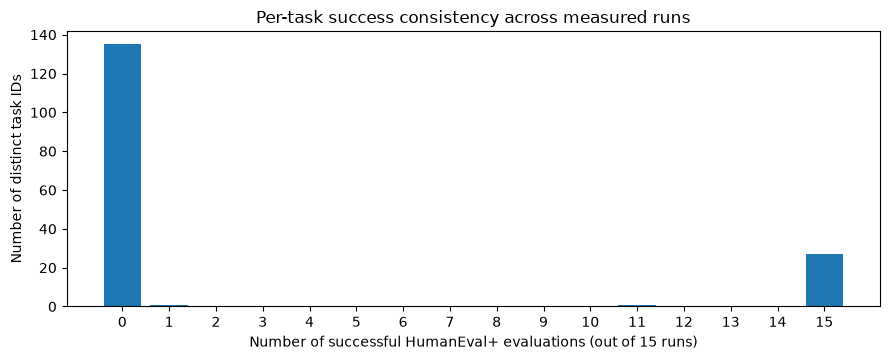

,task_id,passes,base_passes,distinct_solutions,pass_frequency (%)
26,HumanEval/121,1,1,2,6.67
122,HumanEval/61,11,11,5,73.33


In [13]:
if not measured.empty:
  total_runs = measured.run.nunique()
  task_profile = (measured.groupby("task_id", as_index=False)
    .agg(passes=("plus_pass", "sum"),
         base_passes=("base_pass", "sum"),
         distinct_solutions=("solution", "nunique")))
  task_profile["pass_frequency (%)"] = 100 * task_profile.passes / total_runs
  task_profile["category"] = np.select(
    [task_profile.passes.eq(0), task_profile.passes.eq(total_runs)],
    ["never passed", "passed every run"],
    default="mixed outcomes",
  )
  profile_summary = (task_profile.category.value_counts()
    .reindex(["never passed", "mixed outcomes", "passed every run"], fill_value=0)
    .rename_axis("category").reset_index(name="tasks"))
  display(profile_summary)

  histogram = task_profile.passes.value_counts().reindex(range(total_runs + 1), fill_value=0)
  fig, ax = plt.subplots(figsize=(9, 3.7))
  ax.bar(histogram.index, histogram.values)
  ax.set_xlabel(f"Number of successful HumanEval+ evaluations (out of {total_runs} runs)")
  ax.set_ylabel("Number of distinct task IDs")
  ax.set_title("Per-task success consistency across measured runs")
  ax.set_xticks(histogram.index)
  plt.tight_layout()
  plt.show()

  variable_tasks = task_profile[task_profile.category == "mixed outcomes"].copy()
  display(variable_tasks.sort_values(["passes", "task_id"])[
    ["task_id", "passes", "base_passes", "distinct_solutions", "pass_frequency (%)"]
  ].round(2))


## 8. Paired comparison of concurrency settings (exploratory)

Use `c8` as a **reference condition**, because it appears in the original experimental plan. For each task, calculate the average of its repetitions within each concurrency; then compute the difference to `c8` and bootstrap **the same task IDs on both sides**. This is more informative than comparing independent intervals or treating the 15 runs as independent problems.

These are **exploratory contrasts**, not a randomized serving-system experiment. The 95% intervals do not include full uncertainty about future runs and are not multiplicity-adjusted for the four contrasts. **Neither non-significance nor zero observed differences establish equivalence.** We can select concurrency on collection cost if capability remains descriptively stable, but this dataset cannot prove concurrency has no effect.


In [14]:
if not measured.empty:
  task_setting = (measured.groupby(["task_id", "concurrency"])["plus_pass"]
    .mean().unstack("concurrency").reindex(TASK_IDS))
  if 8 not in task_setting.columns:
    print("c8 reference missing; no paired concurrency comparison calculated")
  else:
    rng = np.random.default_rng(BOOTSTRAP_SEED + 200)
    idx = rng.integers(0, len(TASK_IDS), size=(BOOTSTRAP_DRAWS, len(TASK_IDS)))
    comparisons = []
    for concurrency in sorted(task_setting.columns):
      if concurrency == 8:
        continue
      difference = (task_setting[concurrency] - task_setting[8]).to_numpy(dtype=float)
      if np.isnan(difference).any():
        raise ValueError(f"Missing task/concurrency observations for c{concurrency}")
      bootstrap = 100 * difference[idx].mean(axis=1)
      low, high = np.quantile(bootstrap, [0.025, 0.975])
      comparisons.append({
        "contrast": f"c{concurrency} - c8",
        "observed plus difference (pp)": 100 * difference.mean(),
        "95% task CI low (pp)": low,
        "95% task CI high (pp)": high,
        "tasks with differing empirical pass frequency": int(np.count_nonzero(difference)),
      })
    display(pd.DataFrame(comparisons).round(3))


,contrast,observed plus difference (pp),95% task CI low (pp),95% task CI high (pp),tasks with differing empirical pass frequency
0,c32 - c8,-0.203,-0.610,0.0,1
1,c64 - c8,-0.610,-1.626,0.0,2
2,c128 - c8,-0.203,-0.610,0.0,1
3,c256 - c8,-0.610,-1.626,0.0,2


## 9. Generation diagnostics (not capability metrics)

`finish_reason` is the **raw server response reason**. In this protocol, stopping strings are applied **locally after the server returns its text**. Consequently, `finish_reason == "length"` does **not** prove that the *evaluated* code is incomplete: a stop marker may have occurred earlier in the text and the recorded completion may already have been truncated at that marker.

The displayed raw results contain **870/2,460 (35.37%)** responses marked `length`. Their observed HumanEval+ success rate is **27.59%**, versus **11.13%** for `stop`. These are **unadjusted associations**, heavily confounded by which tasks produce longer outputs; do not interpret the gap as a benefit of token limits or as the effect of `finish_reason`. Include every task in the correctness denominator, regardless of finish reason.


In [15]:
generation_paths = sorted(RESULTS_ROOT.glob("generated/c*/*.jsonl"))
generation_paths += sorted(RESULTS_ROOT.glob("gemma-2b_run*.jsonl"))
generation_rows = []
for path in generation_paths:
  match = re.fullmatch(r"(?P<model>[A-Za-z0-9._-]+)_run-(?P<run>\d+)", path.stem)
  c = re.fullmatch(r"c([1-9]\d*)", path.parent.name)
  if match and c and match["model"] == MODEL:
    run = f"c{int(c[1])}_{MODEL}_run-{int(match['run'])}"
  elif path.parent == RESULTS_ROOT and re.fullmatch(r"gemma-2b_run\d+", path.stem):
    run = path.stem
  else:
    continue
  for line in path.read_text(encoding="utf-8").splitlines():
    if not line.strip():
      continue
    record = json.loads(line)
    generation_rows.append({
      "run": run,
      "task_id": record["task_id"],
      "finish_reason": record.get("finish_reason"),
      "completion_tokens": (record.get("usage") or {}).get("completion_tokens"),
    })

if generation_rows:
  generation = pd.DataFrame(generation_rows)
  if generation.duplicated(["run", "task_id"]).any():
    raise ValueError("Duplicate generation rows")
  display(pd.crosstab(generation.run, generation.finish_reason))
  joined = outcomes.merge(generation, on=["run", "task_id"], validate="one_to_one")
  if len(joined):
    display(joined.groupby("finish_reason", as_index=False)
      .agg(tasks=("task_id", "size"), plus_pass_rate=("plus_pass", "mean"))
      .assign(plus_pass_rate=lambda d: (d.plus_pass_rate * 100).round(2)))
else:
  print("Generation JSONL files unavailable; evaluation statistics remain valid.")

finish_reason,length,stop
run,,
c128_google--gemma-2b_run-1,58,106
c128_google--gemma-2b_run-2,58,106
c128_google--gemma-2b_run-3,60,104
c256_google--gemma-2b_run-1,57,107
c256_google--gemma-2b_run-2,59,105
c256_google--gemma-2b_run-3,55,109
c32_google--gemma-2b_run-1,62,102
c32_google--gemma-2b_run-2,57,107
c32_google--gemma-2b_run-3,56,108


,finish_reason,tasks,plus_pass_rate
0,length,870,27.59
1,stop,1590,11.13


### 9.1. Optional generation duration and completeness metadata

Wall-clock duration is supplementary **experimental cost**, not model capability. Only `timing_scope=full_run` is comparable as a complete 164-task generation; resumed segments must not be mixed with full runs. Timing can be absent for runs generated before the `.date.txt` instrumentation was added.


In [16]:
if not measured.empty:
  timing_records = []
  run_metadata = run_scores[["run", "concurrency", "repetition"]].drop_duplicates()
  for record in run_metadata.itertuples(index=False):
    name = f"{MODEL}_run-{record.repetition}"
    directory = RESULTS_ROOT / "generated" / f"c{record.concurrency}"
    date_path = directory / f"{name}.date.txt"
    manifest_path = directory / f"{name}.manifest.json"
    timing = {}
    if date_path.is_file():
      timing = dict(line.split("=", 1) for line in
        date_path.read_text(encoding="utf-8").splitlines() if "=" in line)
    elif manifest_path.is_file():
      timing = json.loads(manifest_path.read_text(encoding="utf-8")).get("timing") or {}
    timing_records.append({
      "run": record.run,
      "concurrency": record.concurrency,
      "timing_scope": timing.get("timing_scope", "unavailable"),
      "elapsed_seconds": float(timing["elapsed_seconds"]) if timing.get("elapsed_seconds") else np.nan,
    })
  timings = pd.DataFrame(timing_records)
  display(timings.sort_values(["concurrency", "run"]).round(2))
  comparable = timings[timings.timing_scope == "full_run"]
  if len(comparable):
    display(comparable.groupby("concurrency").elapsed_seconds.agg(
      runs="count", mean_seconds="mean", median_seconds="median", sd_seconds="std"
    ).round(2))
  else:
    print("No complete-run timings available; timing comparisons omitted")


,run,concurrency,timing_scope,elapsed_seconds
12,c8_google--gemma-2b_run-1,8,full_run,86.86
13,c8_google--gemma-2b_run-2,8,full_run,86.94
14,c8_google--gemma-2b_run-3,8,full_run,86.80
6,c32_google--gemma-2b_run-1,32,full_run,30.36
7,c32_google--gemma-2b_run-2,32,full_run,28.06
8,c32_google--gemma-2b_run-3,32,full_run,27.71
9,c64_google--gemma-2b_run-1,64,full_run,19.12
10,c64_google--gemma-2b_run-2,64,full_run,18.21
11,c64_google--gemma-2b_run-3,64,full_run,18.89
0,c128_google--gemma-2b_run-1,128,full_run,12.90


,runs,mean_seconds,median_seconds,sd_seconds
concurrency,,,,
8,3,86.86,86.86,0.07
32,3,28.71,28.06,1.44
64,3,18.74,18.89,0.47
128,3,12.97,13.00,0.07
256,3,12.42,12.50,0.14


## 11. Interpretation and thesis implications

The quantitative conclusions are consolidated in the dynamically generated interpretation at the end of this notebook. Key boundaries: correctness is evaluated against a fixed suite of 164 programs; concurrency is not a capability score; repeated runs on the same tasks do not expand task coverage; and an identical score can hide changes in the generated solutions.

**Methodological reference:** Jiawei Liu et al., *Is Your Code Generated by ChatGPT Really Correct? Rigorous Evaluation of Large Language Models for Code Generation*, NeurIPS 2023. HumanEval+ extends the original tests to detect additional incorrect solutions. See https://proceedings.neurips.cc/paper_files/paper/2023/hash/43e9d647ccd3e4b7b5baab53f0368686-Abstract.html .


### 11.1. Interpretation generated from the current inputs

The next cell generates a short, updateable summary based on the raw results found on this machine. It explicitly distinguishes between-run variation, task-selection sensitivity, and per-task output instability. For thesis writing, keep the empirical numbers tied to the pinned model, prompting protocol and evaluator version rather than generalizing them to all code-generation tasks.


In [17]:
if not measured.empty:
  overall_plus = run_scores.plus_score.mean()
  overall_base = run_scores.base_score.mean()
  plus_sd = run_scores.plus_score.std(ddof=1)
  plus_median = run_scores.plus_score.median()
  per_setting = run_scores.groupby("concurrency").plus_score.mean()
  task_ci = interval_table[
    (interval_table.benchmark == "HumanEval+") & (interval_table.group == "overall")
  ].iloc[0]
  disagreement_min = 100 * min(
    frame.groupby("task_id").solution.nunique().gt(1).mean()
    for _, frame in measured.groupby("concurrency")
  )
  disagreement_max = 100 * max(
    frame.groupby("task_id").solution.nunique().gt(1).mean()
    for _, frame in measured.groupby("concurrency")
  )
  display(Markdown(f"""
**Summary for the current {len(run_scores)} complete evaluated runs ({measured.task_id.nunique()} task IDs):**

- **Primary capability:** HumanEval+ joint pass@1 **{overall_plus:.2f}%** (run-level median **{plus_median:.2f}%**, run-level SD **{plus_sd:.2f} pp**). Original HumanEval pass@1 is **{overall_base:.2f}%**. The **{overall_base - overall_plus:.2f} pp** decrease measures failures additionally exposed by the stricter test suite on the *same solutions*.
- **Task-selection sensitivity:** clustered task-bootstrap 95% interval for the overall HumanEval+ score **{task_ci['95% task CI low (%)']:.2f}–{task_ci['95% task CI high (%)']:.2f}%**. The width is about variation over *which tasks* are included, not over the next serving run.
- **Stability across the tested settings:** concurrency-group means span **{per_setting.min():.2f}–{per_setting.max():.2f}%**. This is a descriptive result of the tested protocol; it is not a proof of statistical equivalence or a causal effect estimate.
- **Raw-output repeatability:** depending on concurrency, **{disagreement_min:.2f}–{disagreement_max:.2f}%** of task identities have at least two different full solution strings across the three repeated generations. Do not conflate changed strings with changed correctness.
- **Limits for the thesis:** a single model, 164 fixed prompts, three repeats per concurrency, zero-temperature generation and local stop processing cannot support claims about model ranking, general programming competence, or all possible serving configurations. Comparison of further models should pair their outcomes on the same task identities and use the same evaluation protocol.
"""))



**Summary for the current 15 complete evaluated runs (164 task IDs):**

- **Primary capability:** HumanEval+ joint pass@1 **16.95%** (run-level median **17.07%**, run-level SD **0.34 pp**). Original HumanEval pass@1 is **21.99%**. The **5.04 pp** decrease measures failures additionally exposed by the stricter test suite on the *same solutions*.
- **Task-selection sensitivity:** clustered task-bootstrap 95% interval for the overall HumanEval+ score **11.59–22.89%**. The width is about variation over *which tasks* are included, not over the next serving run.
- **Stability across the tested settings:** concurrency-group means span **16.67–17.28%**. This is a descriptive result of the tested protocol; it is not a proof of statistical equivalence or a causal effect estimate.
- **Raw-output repeatability:** depending on concurrency, **15.24–25.61%** of task identities have at least two different full solution strings across the three repeated generations. Do not conflate changed strings with changed correctness.
- **Limits for the thesis:** a single model, 164 fixed prompts, three repeats per concurrency, zero-temperature generation and local stop processing cannot support claims about model ranking, general programming competence, or all possible serving configurations. Comparison of further models should pair their outcomes on the same task identities and use the same evaluation protocol.
